# 05 · SECOM: predicting failing runs from process sensors

**Goal:** flag failing production runs from 590 anonymised sensor readings, and find which sensors drive the prediction.

**Setup** (decided in notebook 02)
- **Time-ordered split:** train on the earliest 70% of runs, test on the latest 30%. This is how a fab would deploy the model, and notebook 02 showed the fail rate drifts.
- **No leakage:** sensor dropping, imputation and scaling are fitted on training runs only, inside a scikit-learn `Pipeline`.
- **Metrics:** PR-AUC (compare with the fail rate, which is what a random model scores), ROC-AUC, and *recall at 5% false alarms*: the share of failing runs caught if engineers inspect 5% of good runs. With only ~26 failing test runs, every number gets a bootstrap 95% interval.
- **Models:** L1 logistic regression (sparse, interpretable) and LightGBM, with fixed settings chosen before looking at the test period.

In [1]:
%matplotlib inline
import json, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import PrecisionRecallDisplay, roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict

from wafer import secom as S
from wafer.data import load_secom

warnings.filterwarnings('ignore', category=UserWarning)
FIG_DIR = Path('../reports/figures'); FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.precision', 3)

In [2]:
X, meta = load_secom()
y = meta['fail'].astype(int).to_numpy()
tr, te = S.time_split(meta['timestamp'])
pd.DataFrame({
    'runs': [len(tr), len(te)],
    'fails': [y[tr].sum(), y[te].sum()],
    'fail_rate': [y[tr].mean(), y[te].mean()],
    'from': [meta['timestamp'].iloc[tr].min(), meta['timestamp'].iloc[te].min()],
    'to': [meta['timestamp'].iloc[tr].max(), meta['timestamp'].iloc[te].max()],
}, index=['train', 'test'])

,runs,fails,fail_rate,from,to
train,1096,78,0.071,2008-07-19 11:55:00,2008-09-26 02:26:00
test,471,26,0.055,2008-09-26 03:12:00,2008-10-17 06:07:00


## 1. Sensor cleaning (fitted on training runs only)

In [3]:
cleaner = S.SensorCleaner().fit(X.iloc[tr])
print(f'{cleaner.n_input_} sensors -> {len(cleaner.columns_)} after dropping '
      'mostly-missing, constant and near-duplicate (|r| > 0.95) sensors')

590 sensors -> 274 after dropping mostly-missing, constant and near-duplicate (|r| > 0.95) sensors


## 2. Random cross-validation vs. time-ordered test

Many published SECOM results use random cross-validation. Comparing it with the time-ordered test shows how much that overstates performance.

In [4]:
%%time
MODELS = {'Logistic (L1)': lambda: S.make_logreg(0.05), 'LightGBM': S.make_lgbm}
rows, test_scores = [], {}
for name, make in MODELS.items():
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0)
    cv_pr = [S.score_all(y[b], make().fit(X.iloc[a], y[a]).predict_proba(X.iloc[b])[:, 1])['pr_auc']
             for a, b in cv.split(X, y)]
    model = make().fit(X.iloc[tr], y[tr])
    p = model.predict_proba(X.iloc[te])[:, 1]
    test_scores[name] = (model, p)
    r = S.score_all(y[te], p)
    lo, hi = S.bootstrap_ci(y[te], p)
    rlo, rhi = S.bootstrap_ci(y[te], p, roc_auc_score)
    rows.append({
        'model': name,
        'random-CV PR-AUC': f'{np.mean(cv_pr):.3f} ± {np.std(cv_pr):.3f}',
        'CV fail rate': f'{y.mean():.3f}',
        'time-split PR-AUC': f"{r['pr_auc']:.3f} [{lo:.3f}, {hi:.3f}]",
        'test fail rate': f"{r['base_rate']:.3f}",
        'time-split ROC-AUC': f"{r['roc_auc']:.3f} [{rlo:.3f}, {rhi:.3f}]",
        'recall @ 5% false alarms': f"{r['recall_at_5pct_fpr']:.3f}",
    })
results = pd.DataFrame(rows).set_index('model')
results

CPU times: user 48.8 s, sys: 150 ms, total: 49 s
Wall time: 34.2 s


,random-CV PR-AUC,CV fail rate,time-split PR-AUC,test fail rate,time-split ROC-AUC,recall @ 5% false alarms
model,,,,,,
Logistic (L1),0.192 ± 0.040,0.066,"0.082 [0.044, 0.172]",0.055,"0.539 [0.420, 0.664]",0.154
LightGBM,0.196 ± 0.052,0.066,"0.086 [0.054, 0.143]",0.055,"0.662 [0.570, 0.749]",0.038


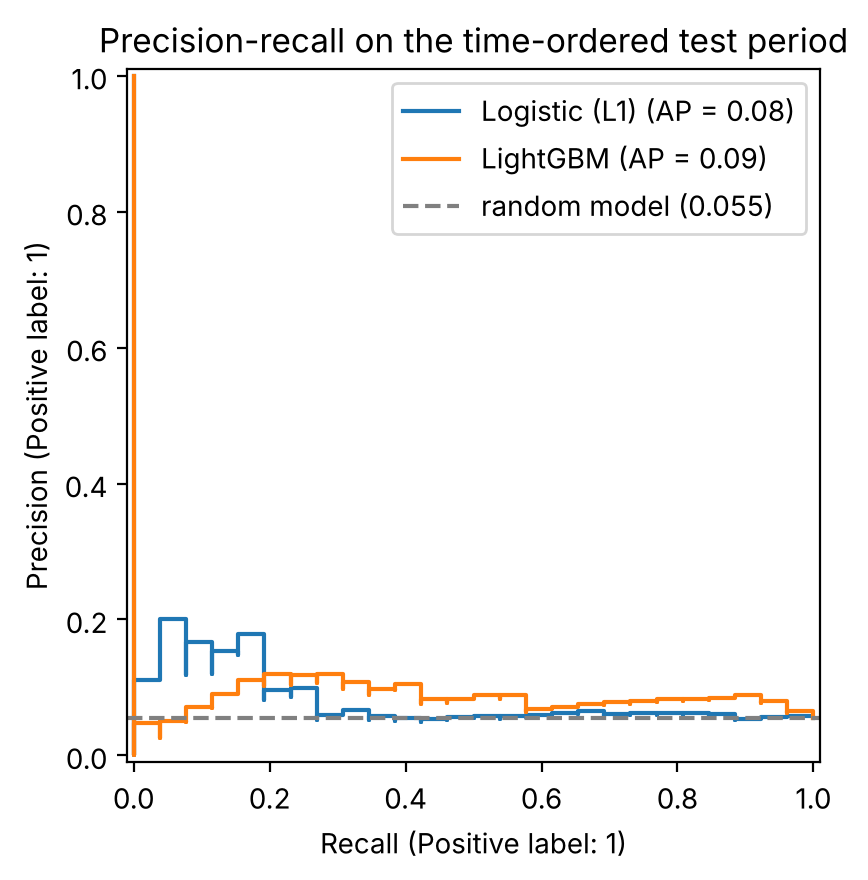

In [5]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for name, (_, p) in test_scores.items():
    PrecisionRecallDisplay.from_predictions(y[te], p, name=name, ax=ax)
ax.axhline(y[te].mean(), ls='--', c='gray', label=f'random model ({y[te].mean():.3f})')
ax.set_title('Precision-recall on the time-ordered test period'); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / 'secom_pr_curve.png', dpi=150)

## 3. Why is the time-ordered test so much harder? Checking for drift

*Adversarial validation:* train a classifier to tell training-period runs from test-period runs. If it can (AUC near 1), the sensor readings themselves changed over time.

In [6]:
period = np.zeros(len(y)); period[te] = 1
Xc = S.SensorCleaner().fit(X).transform(X)
adv = lgb.LGBMClassifier(n_estimators=200, num_leaves=15, verbose=-1)
adv_p = cross_val_predict(adv, Xc, period, method='predict_proba',
                          cv=StratifiedKFold(5, shuffle=True, random_state=0))[:, 1]
adv_auc = roc_auc_score(period, adv_p)
imp = pd.Series(adv.fit(Xc, period).booster_.feature_importance('gain'), index=Xc.columns)
print(f'adversarial AUC (train period vs test period): {adv_auc:.3f}')
(imp / imp.sum()).sort_values(ascending=False).head(5).rename('share of gain')

adversarial AUC (train period vs test period): 0.996


f116    0.400
f542    0.116
f058    0.087
f132    0.033
f122    0.028
Name: share of gain, dtype: float64

## 4. Which sensors drive the prediction? (SHAP on LightGBM, coefficients for L1)

L1 logistic keeps 63 sensors; 7 of the top 20 overlap with SHAP


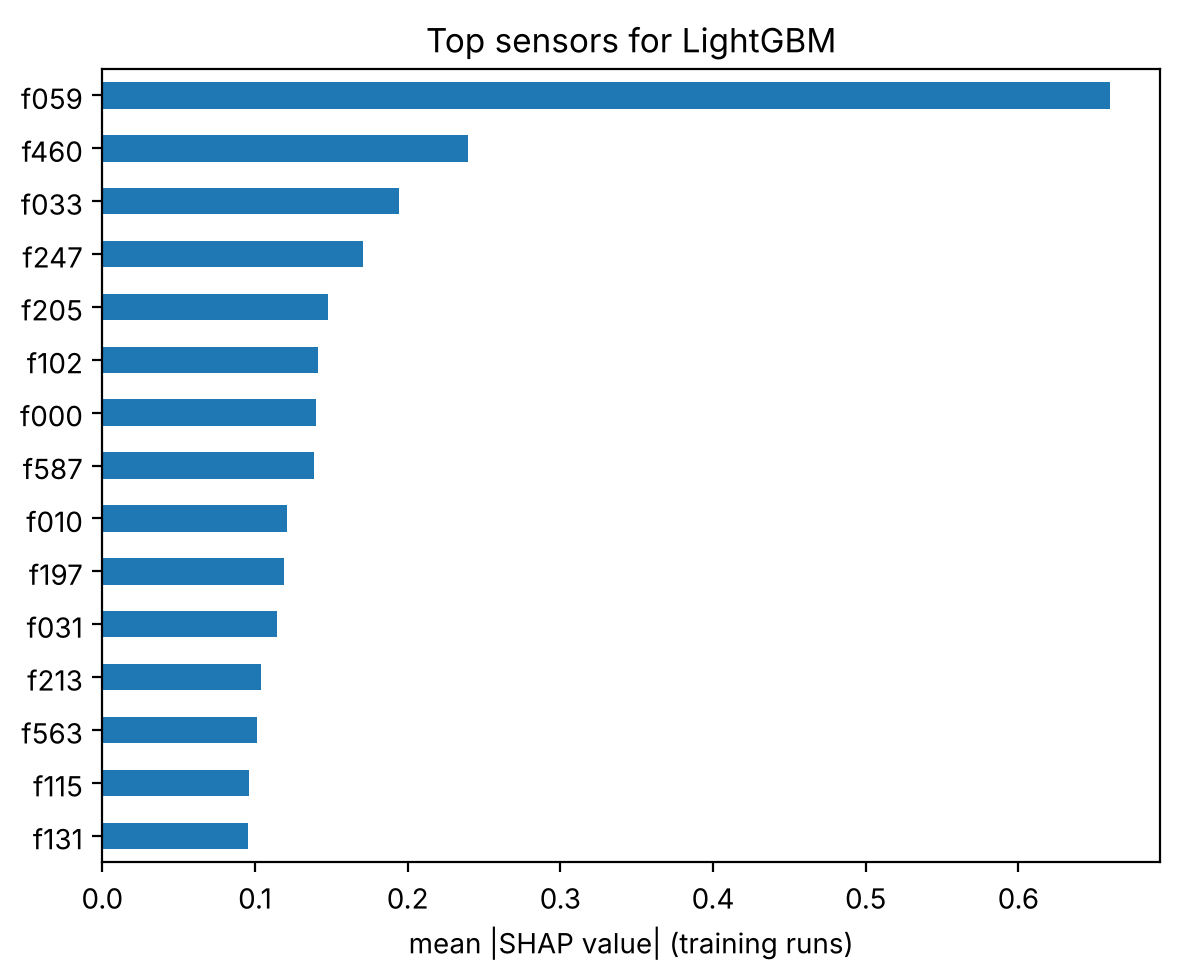

In [7]:
gbm, _ = test_scores['LightGBM']
shap = S.lgbm_shap(gbm, X.iloc[tr])
top = shap.abs().mean().sort_values(ascending=False)
lr, _ = test_scores['Logistic (L1)']
coef = pd.Series(lr.named_steps['clf'].coef_[0], index=lr.named_steps['clean'].columns_)
nonzero = coef[coef != 0].abs().sort_values(ascending=False)
print(f'L1 logistic keeps {len(nonzero)} sensors; '
      f'{len(set(top.index[:20]) & set(nonzero.index[:20]))} of the top 20 overlap with SHAP')
ax = top.head(15).sort_values().plot.barh(figsize=(6, 5))
ax.set_xlabel('mean |SHAP value| (training runs)')
ax.set_title('Top sensors for LightGBM')
plt.tight_layout(); plt.savefig(FIG_DIR / 'secom_shap_top.png', dpi=150)

## 5. Do the top sensors keep their signal over time?

Single-sensor ROC-AUC in the training period vs the test period (0.5 = no signal).

In [8]:
def single_auc(col, idx):
    v = X[col].fillna(X[col].iloc[tr].median()).iloc[idx]
    return roc_auc_score(y[idx], v)

stab = pd.DataFrame({
    'train AUC': [single_auc(c, tr) for c in top.index[:10]],
    'test AUC': [single_auc(c, te) for c in top.index[:10]],
}, index=top.index[:10])
# Direction-free strength: 0.5 = none, 1.0 = perfect
stab['train strength'] = (stab['train AUC'] - 0.5).abs() + 0.5
stab['test strength'] = (stab['test AUC'] - 0.5).abs() + 0.5
stab

,train AUC,test AUC,train strength,test strength
f059,0.756,0.473,0.756,0.527
f460,0.599,0.496,0.599,0.504
f033,0.615,0.584,0.615,0.584
f247,0.666,0.517,0.666,0.517
f205,0.652,0.512,0.652,0.512
f102,0.424,0.396,0.576,0.604
f000,0.379,0.596,0.621,0.596
f587,0.582,0.496,0.582,0.504
f010,0.568,0.492,0.568,0.508
f197,0.603,0.468,0.603,0.532


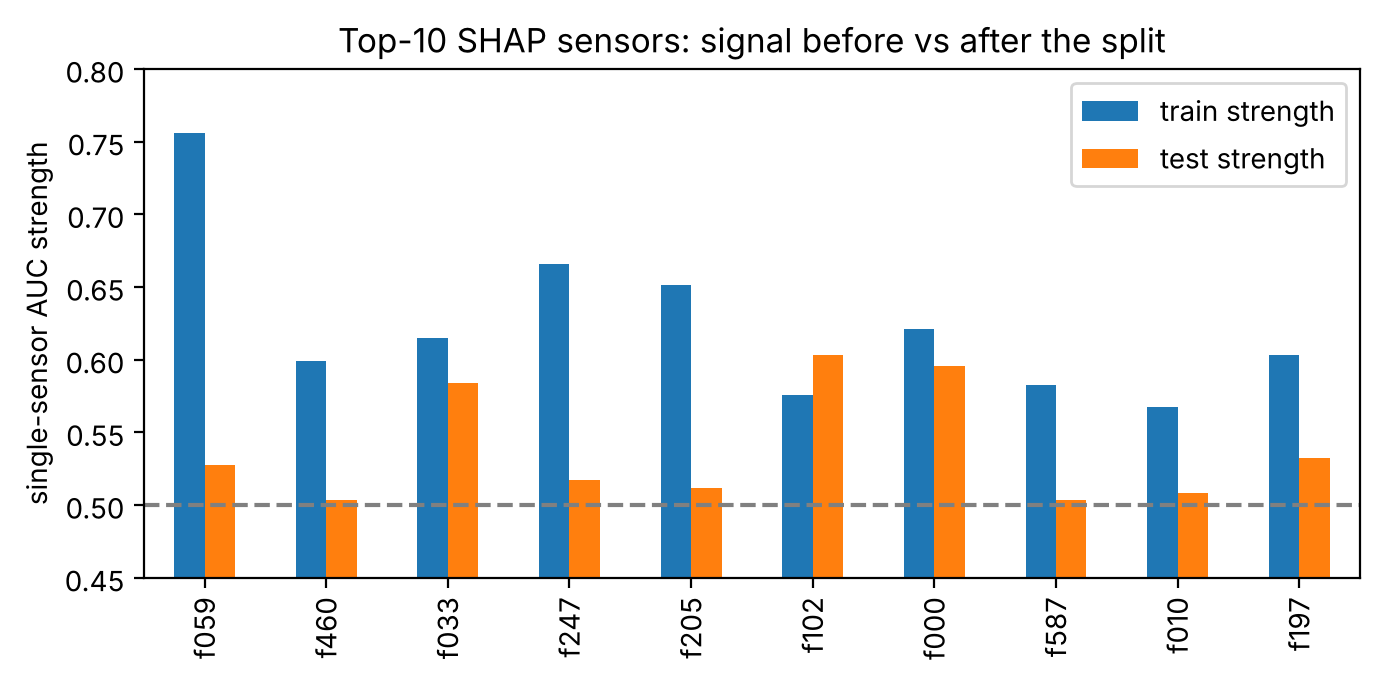

In [9]:
ax = stab[['train strength', 'test strength']].plot.bar(figsize=(7, 3.5))
ax.axhline(0.5, c='gray', ls='--'); ax.set_ylim(0.45, 0.8)
ax.set_ylabel('single-sensor AUC strength'); ax.set_title('Top-10 SHAP sensors: signal before vs after the split')
plt.tight_layout(); plt.savefig(FIG_DIR / 'secom_sensor_drift.png', dpi=150)

## 6. Save results for the README

In [10]:
out = {name: S.score_all(y[te], p) for name, (_, p) in test_scores.items()}
for name, (_, p) in test_scores.items():
    out[name]['pr_auc_95ci'] = S.bootstrap_ci(y[te], p)
out['adversarial_auc'] = adv_auc
out['top_sensors_shap'] = top.head(10).round(4).to_dict()
Path('../reports/results_secom.json').write_text(json.dumps(out, indent=2))
out

{'Logistic (L1)': {'pr_auc': 0.08207163624888217,
  'roc_auc': 0.5394122731201383,
  'recall_at_5pct_fpr': 0.15384615384615385,
  'base_rate': 0.055201698513800426,
  'pr_auc_95ci': (0.044099201994421765, 0.1721232104650137)},
 'LightGBM': {'pr_auc': 0.08621273153869943,
  'roc_auc': 0.662057044079516,
  'recall_at_5pct_fpr': 0.038461538461538464,
  'base_rate': 0.055201698513800426,
  'pr_auc_95ci': (0.05443363986230321, 0.142851418103954)},
 'adversarial_auc': 0.9964607838579199,
 'top_sensors_shap': {'f059': 0.6598,
  'f460': 0.2393,
  'f033': 0.1946,
  'f247': 0.1709,
  'f205': 0.1478,
  'f102': 0.1411,
  'f000': 0.1397,
  'f587': 0.1389,
  'f010': 0.1207,
  'f197': 0.1192}}

## Findings

**Headline: on a realistic time-ordered test, process sensors barely predict failures, and the reason is drift, not the model.**

| | Logistic (L1) | LightGBM |
|---|---|---|
| Random-CV PR-AUC (fail rate 0.066) | 0.192 ± 0.040 | 0.196 ± 0.052 |
| **Time-split PR-AUC** (fail rate 0.055) | 0.082 [0.044, 0.172] | 0.086 [0.054, 0.143] |
| Time-split ROC-AUC | 0.539 [0.420, 0.664] | 0.662 [0.570, 0.749] |
| Recall at 5% false alarms | 0.15 (4 of 26) | 0.04 (1 of 26) |

*Brackets: bootstrap 95% intervals. Test period: 471 runs, 26 failures.*

**1. Random cross-validation overstates performance about 2x.** Shuffled CV gives PR-AUC ~0.19, about 3x the fail rate. On the later, unseen time period it drops to ~0.08, only 1.5x the fail rate, and the confidence interval reaches down to random. Many published SECOM results use shuffled CV; this is why they look better than a model would perform in a fab.

**2. The sensor readings themselves shift over time.** A classifier can tell training-period runs from test-period runs with **AUC 0.996** (adversarial validation). A handful of sensors (f116, f542, f058) account for most of the difference, which looks like recalibration, maintenance or a process change around late September.

**3. The sensor–failure relationship changes too.** `f059` is by far the most important sensor in training (top SHAP value, and the largest L1 coefficient), and on its own separates failures with AUC 0.76. In the test period it carries no signal (0.47). Of the 10 most important sensors, 7 lose most of their signal after the split; only `f033`, `f102` and `f000` keep theirs. This is *concept drift*: the model learned real patterns, but they stopped holding.

**4. The two models agree on what mattered.** L1 logistic regression keeps 63 of 274 sensors; 7 of its top 20 overlap with LightGBM's top 20 SHAP sensors, and both rank `f059` first. So the signal in the training period is real, not a modelling artefact.

**What this means for a fab**
- A static model trained once is **not** ready to run as a fail alarm: at a 5% false-alarm budget it catches at most 4 of 26 failures.
- It *is* useful as a **sensor shortlist** for engineers: `f033`, `f102` and `f000` predicted failures both before and after the shift (the most trustworthy leads), `f059` was the strongest signal until late September, and `f116`, `f542`, `f058` are the sensors that changed most. All three lists are worth a process-engineering review.
- A next model should favour sensors whose signal is **stable over time**, not just strong in the training window.
- Deployment would need **drift monitoring** (e.g. the adversarial check above run weekly) and **regular retraining** on recent runs.

**Limitations:** only ~3 months of data and 104 failures in total, so every test number has a wide interval. Sensor names are anonymised, so domain interpretation stops at "which sensor", not "which tool".
